In [1]:
import jax
import jax.numpy as jnp

import matplotlib.pyplot as plt

from agfx.gym import create_state, from_amat, enumerate_ancestral_graphs, AncestralGraph
from agfx.special.linear_gaussian import sample_linear_gaussian
from agfx.rewards import create_log_reward, LogRewardType 
from agfx.training import train, LossType
from agfx.policies import GFlowNet
from agfx.evals import eval_marginal

In [2]:
num_nodes = 5
bs = 64
dmid = 64

iterations = int(2e4)
logr_t = LogRewardType.BIC
loss_t = LossType.CB

seed = 42

reward_seed = 43

In [3]:
all_graphs = enumerate_ancestral_graphs(num_nodes)

In [4]:
reward_key = jax.random.key(reward_seed)
# Simulate the data (which is needed for certain reward functions)
data, dir_amat, bidir_amat, *_ = sample_linear_gaussian(
    reward_key, num_nodes, num_samples=600
)
true_graph = from_amat((dir_amat + bidir_amat)[None])

In [5]:
def train_gfn(seed: int, logr_t: LogRewardType, **kwargs):
    key = jax.random.key(seed)
    k1, k2 = jax.random.split(key, 2)

    state = create_state(bs, num_nodes)
    # Create the GFlowNet
    gfn = GFlowNet(num_nodes, dmid)
    # Create the reward function
    logr = create_log_reward(logr_t, data, true_graph, **kwargs)

    gfn, _ = train(gfn, state, k1, logr, iterations, loss_t)
    return gfn, state

In [6]:
# true_marginals, estimated_marginals = eval_marginal(gfn, state, logr, all_graphs, k2)

## Human in the loop

In [7]:
from mpl_preamble import *

In [8]:
from agfx.eitl import QueryMethod, expert, next_query, EIPolicy
from agfx.policies import rollout_many
from agfx.evals import shd

pi = .9 
pi_star = .9

In [9]:
def run(query_method: QueryMethod, seed: int, gfn: GFlowNet, state: AncestralGraph, n: int = 40, steps=None):
    key = jax.random.key(seed) 
    ei_policy = EIPolicy(num_nodes, pi=pi)

    if steps is None:
        steps = list(range(n))

    step_set = set(steps)
    shds = []

    for i in range(max(steps) + 1):
        rel, key = next_query(ei_policy, method=query_method, key=key)
        ans, key = expert(true_graph, pi=pi_star, rel=rel, key=key)
        ei_policy.update(rel, ans)

        if i in step_set:
            samples = rollout_many(gfn, state, key, num_rollouts=20, fpol=ei_policy)
            v = jax.vmap(shd, in_axes=(0, None), out_axes=0)(samples, true_graph)
            shds.append(float(v.mean()))

    return shds

In [10]:
gfn, state = train_gfn(seed, LogRewardType.BIC)

100%|██████████| 20000/20000 [05:25<00:00, 61.45it/s, loss=4.66e-01]


In [11]:
gfn_sparse, state_sparse = train_gfn(seed, LogRewardType.SPARSE, alpha=.5)

100%|██████████| 20000/20000 [00:46<00:00, 426.21it/s, loss=2.92e-01]


In [12]:
steps = [0, 2, 5, 10, 15, 20, 30, 40]
seeds = [42, 84, 126]

shds_entropy = []
shds_random = []
shds_entropy_sparse = []
shds_random_sparse = []

for seed in seeds:
    shds_entropy.append(run(QueryMethod.ENTROPY, seed=seed, gfn=gfn, state=state, steps=steps))
    shds_random.append(run(QueryMethod.RANDOM, seed=seed, gfn=gfn, state=state, steps=steps))

    shds_entropy_sparse.append(run(QueryMethod.ENTROPY, seed=seed, gfn=gfn_sparse, state=state_sparse, steps=steps))
    shds_random_sparse.append(run(QueryMethod.RANDOM, seed=seed, gfn=gfn_sparse, state=state_sparse, steps=steps))

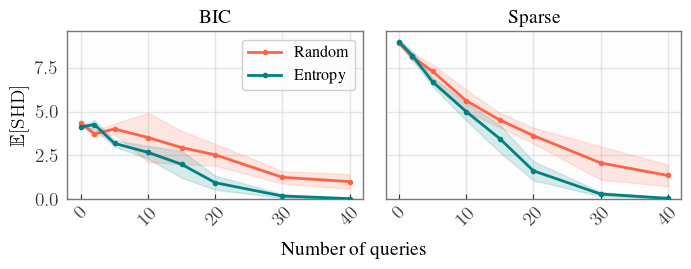

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(7, 3), sharey=True)

def plot(ax, v, label, c):
    v = jnp.array(v)
    m = v.mean(axis=0)
    s = v.std(axis=0)
    xs = jnp.array(steps)
    ax.plot(xs, m, label=label, color=c, marker="o", markersize=3, zorder=3)
    ax.fill_between(xs, m - s, m + s, alpha=0.15, color=c)

plot(axes[0], shds_random, "Random", "tomato")
plot(axes[0], shds_entropy, "Entropy", "teal")
axes[0].set_title("BIC")
axes[0].set_ylabel(r"$\mathbb{E}[\mathrm{SHD}]$")
axes[0].legend(loc="upper right", framealpha=0.9)

plot(axes[1], shds_random_sparse, "Random", "tomato")
plot(axes[1], shds_entropy_sparse, "Entropy", "teal")
axes[1].set_title("Sparse")

for ax in axes:
    ax.set_ylim(bottom=0)
    ax.tick_params(axis="x", rotation=45)

fig.supxlabel("Number of queries", y=.1, fontsize=14)
plt.tight_layout()
plt.savefig("figures/random_querying.pdf", bbox_inches="tight")

<Figure size 400x400 with 0 Axes>

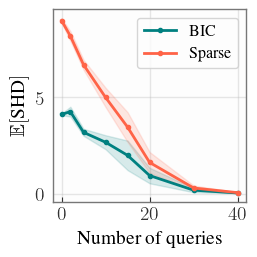

In [16]:
plt.figure(figsize=(4, 4))

_, ax = plt.subplots()

plot(ax, shds_entropy, label="BIC", c="teal")
plot(ax, shds_entropy_sparse, label="Sparse", c="tomato")

plt.ylabel("$\\mathbb{E}[\\text{SHD}]$")
plt.xlabel("Number of queries")

plt.legend()

plt.savefig("figures/sparse_rewards_entropy_querying.pdf", bbox_inches="tight")